# Analyse de données de roulements — IMS Bearing Dataset
### Durée de vie résiduelle (RUL) et classification Healthy/Faulty

Notebook complet : bibliothèques, prétraitement, EDA, extraction de caractéristiques, data labelling,
modèles d'apprentissage machine classiques (LR, Random Forest, Decision Tree, SVM, KNN, XGBoost),
prédiction de la durée de vie résiduelle (LSTM puis hybridation CNN-LSTM) et jumeau numérique.

**Contexte** : le dataset IMS (NASA / University of Cincinnati) contient **3 tests** (3 campagnes
d'essai indépendantes). Dans chaque test, 4 roulements tournent à 2000 tr/min sous 6000 lbs ;
toutes les 10 minutes, 1 seconde de vibration est enregistrée à **20 kHz** (20 480 points par fichier).
Chaque test s'arrête lorsqu'un roulement casse :

| Test | Durée | Roulement(s) en panne | Type de défaut |
|---|---|---|---|
| 1st test | ≈ 34,5 jours | Bearing 3 et Bearing 4 | bague intérieure / élément roulant |
| **2nd test** | ≈ 6,8 jours | **Bearing 1** (1re colonne) | bague extérieure |
| 3rd test | ≈ 44,7 jours | Bearing 3 | bague extérieure |

L'EDA, l'extraction de caractéristiques et la classification portent sur le **2nd test** ;
la prédiction de la RUL utilise les **4 roulements qui vont jusqu'à la panne** dans les 3 tests.

## 1. Import des bibliothèques

In [1]:
# !pip install pandas numpy scipy matplotlib seaborn scikit-learn PyWavelets xgboost tensorflow
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore, skew, kurtosis
from scipy.fft import rfft, rfftfreq
from scipy.signal import butter, filtfilt, hilbert
import pywt
import warnings
warnings.filterwarnings('ignore')

# Fonctions communes RUL (fichier rul_lib.py, à côté du notebook)
from rul_lib import (FEATS, WINDOW, FAILURES, N_BASE, load_features, failure_trajectory,
                     degradation_onset, healthy_reference, relative_features, piecewise_rul,
                     sliding_windows, build_lstm, build_cnn_lstm, fit_keras, metrics)

sns.set(color_codes=True)
plt.rcParams['figure.dpi'] = 90
FS = 20000  # fréquence d'échantillonnage des signaux bruts (Hz)
print("Bibliothèques importées avec succès")

Bibliothèques importées avec succès


## 2. Chargement des données

Les fichiers bruts (≈ 6 Go pour les 3 tests) sont traités **une seule fois** par le script
`extract_features.py`, qui calcule pour **chaque fichier et chaque roulement** les caractéristiques
du signal brut (moyenne absolue, RMS, énergie, entropie spectrale, kurtosis, asymétrie, pic, facteur de crête).
Le résultat est stocké dans `cache/features_<test>.csv` (quelques Mo), avec quelques signaux bruts
complets dans `cache/samples_<test>.npz` pour les analyses fréquentielles.

Pour régénérer le cache à partir des fichiers bruts :
```
python extract_features.py "chemin/vers/2nd_test" test2 4
python extract_features.py "chemin/vers/1st_test" test1 8     # 8 canaux : on garde l'axe x
python extract_features.py "chemin/vers/4th_test/txt" test3 4
```
> Les fichiers bruts n'ont **pas d'en-tête** : ils doivent être lus avec `header=None`
> (sinon la première ligne de chaque fichier est perdue).

La moyenne de la valeur absolue par roulement (`MeanAbs`) reproduit le tableau `merged_data` d'origine.

In [2]:
feat2 = load_features('test2')
merged_data = feat2.pivot(index='Date', columns='Bearing', values='MeanAbs').sort_index()
merged_data.columns = ['Bearing 1', 'Bearing 2', 'Bearing 3', 'Bearing 4']

print(f"Nombre d'échantillons temporels : {merged_data.shape[0]}")
print(f"Période : {merged_data.index.min()} -> {merged_data.index.max()}")
merged_data.head()

Nombre d'échantillons temporels : 984
Période : 2004-02-12 10:32:39 -> 2004-02-19 06:22:39


,Bearing 1,Bearing 2,Bearing 3,Bearing 4
Date,,,,
2004-02-12 10:32:39,0.058332,0.071832,0.083244,0.043065
2004-02-12 10:42:39,0.058997,0.074008,0.084439,0.044540
2004-02-12 10:52:39,0.060239,0.074223,0.083922,0.044442
2004-02-12 11:02:39,0.061453,0.073843,0.084462,0.045081
2004-02-12 11:12:39,0.061361,0.075606,0.082837,0.045118


In [3]:
merged_data.tail()

,Bearing 1,Bearing 2,Bearing 3,Bearing 4
Date,,,,
2004-02-19 05:42:39,0.453318,0.161011,0.137444,0.119042
2004-02-19 05:52:39,0.337575,0.132397,0.144997,0.092123
2004-02-19 06:02:39,0.351094,0.152259,0.151296,0.100813
2004-02-19 06:12:39,0.001857,0.003731,0.003656,0.001786
2004-02-19 06:22:39,0.001168,0.000767,0.000716,0.001699


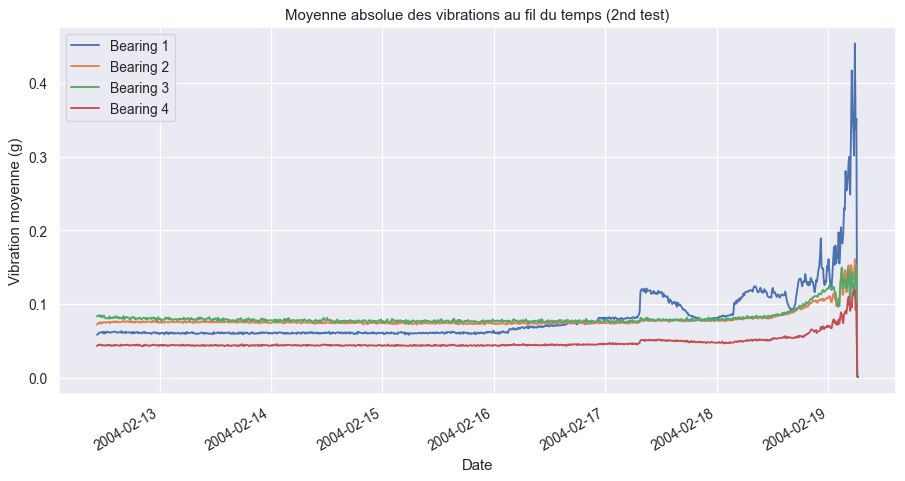

In [4]:
merged_data.plot(figsize=(12, 6))
plt.title('Moyenne absolue des vibrations au fil du temps (2nd test)')
plt.ylabel('Vibration moyenne (g)')
plt.show()

> Les **deux dernières acquisitions** sont quasi nulles (RMS < 0,01) : le capteur a été arrêté
> après la casse. Elles sont exclues de la prédiction de RUL.

## 3. Analyse exploratoire (EDA)

### 3.1 Statistiques sommaires
Ces statistiques décrivent la distribution de la vibration moyenne de chaque roulement.

In [5]:
merged_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Bearing 1,984.0,0.080905,0.040171,0.001168,0.060764,0.062005,0.083222,0.453318
Bearing 2,984.0,0.078532,0.011779,0.000767,0.074232,0.075202,0.077462,0.161011
Bearing 3,984.0,0.081356,0.011596,0.000716,0.076830,0.078197,0.080597,0.151296
Bearing 4,984.0,0.047822,0.009541,0.001699,0.043949,0.044523,0.048110,0.119042


### 3.2 Superposition des roulements

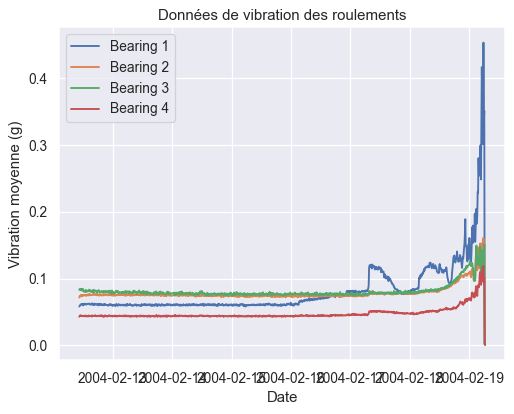

In [6]:
for i in range(4):
    plt.plot(merged_data.iloc[:, i], label=f'Bearing {i + 1}')
plt.xlabel('Date'); plt.ylabel('Vibration moyenne (g)')
plt.title('Données de vibration des roulements'); plt.legend(); plt.show()

### 3.3 Boîtes à moustaches (outliers)

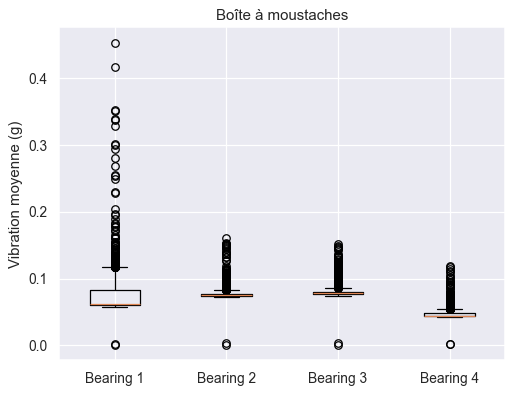

Outliers (|z| > 3) par roulement :
Bearing 1    18
Bearing 2    22
Bearing 3    38
Bearing 4    27
dtype: int64


In [7]:
plt.boxplot(merged_data)
plt.xticks([1, 2, 3, 4], ['Bearing 1', 'Bearing 2', 'Bearing 3', 'Bearing 4'])
plt.ylabel('Vibration moyenne (g)'); plt.title('Boîte à moustaches'); plt.show()

z_scores = merged_data.apply(zscore).abs()
print("Outliers (|z| > 3) par roulement :")
print((z_scores > 3).sum())

### 3.4 Histogrammes

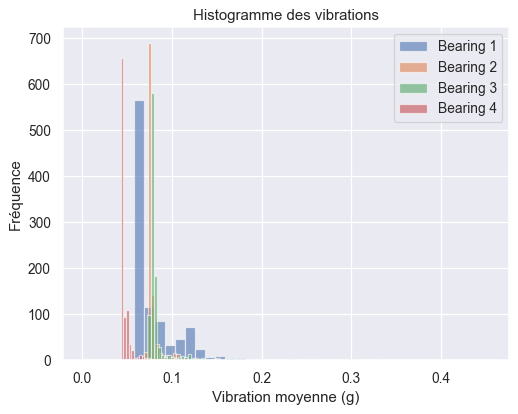

In [8]:
for i in range(4):
    plt.hist(merged_data.iloc[:, i], bins=40, alpha=0.6, label=f'Bearing {i + 1}')
plt.xlabel('Vibration moyenne (g)'); plt.ylabel('Fréquence')
plt.title('Histogramme des vibrations'); plt.legend(); plt.show()

### 3.5 Corrélation entre roulements

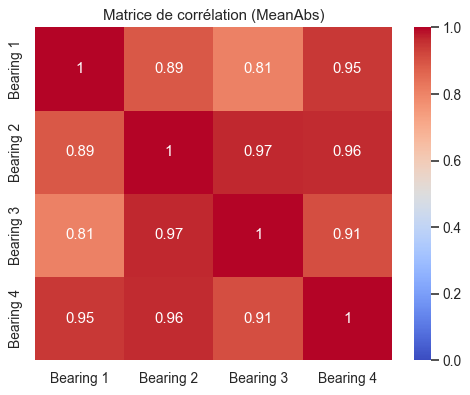

In [9]:
sns.heatmap(merged_data.corr(), annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title('Matrice de corrélation (MeanAbs)'); plt.show()

## 4. Extraction de caractéristiques

### 4.1 Caractéristiques statistiques (sur la série des moyennes)

In [10]:
def extract_statistical_features(df):
    features = pd.DataFrame()
    features['mean'] = df.mean(axis=0)
    features['std'] = df.std(axis=0)
    features['skew'] = df.skew(axis=0)
    features['kurtosis'] = df.kurtosis(axis=0)
    features['max'] = df.max(axis=0)
    features['min'] = df.min(axis=0)
    features['range'] = features['max'] - features['min']
    return features

extract_statistical_features(merged_data)

,mean,std,skew,kurtosis,max,min,range
Bearing 1,0.080905,0.040171,4.187848,24.726709,0.453318,0.001168,0.452149
Bearing 2,0.078532,0.011779,3.106748,19.736561,0.161011,0.000767,0.160244
Bearing 3,0.081356,0.011596,2.484602,15.261470,0.151296,0.000716,0.150579
Bearing 4,0.047822,0.009541,3.729213,20.337947,0.119042,0.001699,0.117344


### 4.2 Normalisation (z-score)

In [11]:
merged_data_normalized = merged_data.apply(lambda x: (x - x.mean()) / x.std())
merged_data_normalized.head()

,Bearing 1,Bearing 2,Bearing 3,Bearing 4
Date,,,,
2004-02-12 10:32:39,-0.561917,-0.568797,0.162846,-0.498591
2004-02-12 10:42:39,-0.545382,-0.384008,0.265860,-0.343997
2004-02-12 10:52:39,-0.514456,-0.365740,0.221310,-0.354263
2004-02-12 11:02:39,-0.484228,-0.398031,0.267894,-0.287278
2004-02-12 11:12:39,-0.486525,-0.248340,0.127698,-0.283378


### 4.3 Analyse fréquentielle (FFT) du signal brut

**Correction importante** : la FFT doit être appliquée au **signal brut** d'une acquisition
(20 480 points échantillonnés à 20 kHz). La série `merged_data` contient une valeur toutes les
**10 minutes** : sa fréquence d'échantillonnage réelle est 1/600 Hz, pas 20 kHz, donc un spectre
« 0–5000 Hz » calculé dessus n'a pas de sens physique.

On compare ici le Bearing 1 **au début du test** (sain), **au milieu** et **10 acquisitions avant la fin** (dégradé).

{'Sain (début)': np.str_('2004.02.12.10.32.39'), 'Milieu du test': np.str_('2004.02.15.20.32.39'), 'Dégradé (fin)': np.str_('2004.02.19.04.52.39')}


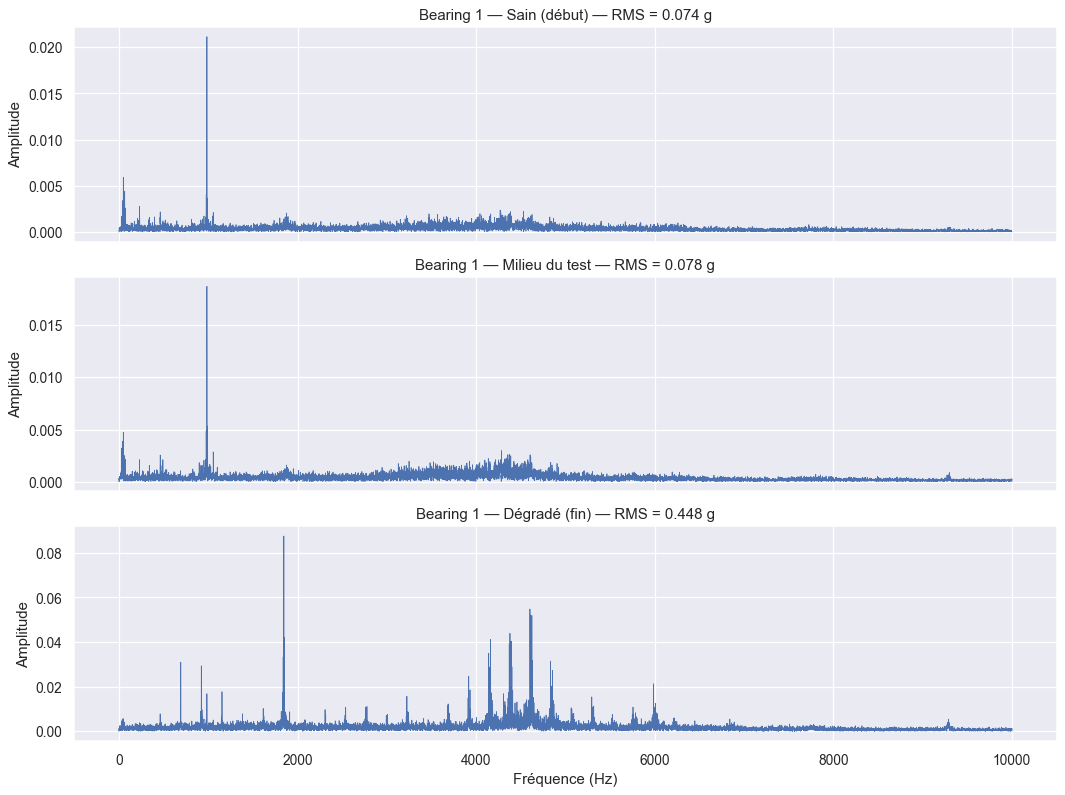

Fréquence de crête (Hz) par roulement :
           Sain (début)  Milieu du test  Dégradé (fin)
Bearing 1    985.351562      985.351562    1846.679688
Bearing 2    985.351562      985.351562     922.851562
Bearing 3    985.351562      985.351562     692.382812
Bearing 4    985.351562      985.351562     461.914062


In [12]:
samples = np.load('cache/samples_test2.npz')
keys = [k for k in samples.files if k != 'names']
names = list(samples['names'])
etats = ['Sain (début)', 'Milieu du test', 'Dégradé (fin)']
print(dict(zip(etats, names)))

def spectrum(x, fs=FS):
    x = x - x.mean()
    return rfftfreq(len(x), 1 / fs), np.abs(rfft(x)) / len(x)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, k, e in zip(axes, keys, etats):
    x = samples[k][:, 0].astype(float)
    f, m = spectrum(x)
    ax.plot(f, m, lw=0.6)
    ax.set_title(f'Bearing 1 — {e} — RMS = {np.sqrt(np.mean(x**2)):.3f} g')
    ax.set_ylabel('Amplitude')
axes[-1].set_xlabel('Fréquence (Hz)'); plt.tight_layout(); plt.show()

def extract_peak_frequency(x, fs=FS):
    f, m = spectrum(x, fs)
    return f[np.argmax(m[1:]) + 1]

print("Fréquence de crête (Hz) par roulement :")
print(pd.DataFrame({e: [extract_peak_frequency(samples[k][:, i].astype(float)) for i in range(4)]
                    for k, e in zip(keys, etats)}, index=[f'Bearing {i+1}' for i in range(4)]))

### 4.4 Filtrage (passe-bande et passe-haut) du signal brut

On applique au signal brut (fs = 20 kHz) :
- un **filtre passe-bande 100–9500 Hz** (Butterworth ordre 5) ;
- un **filtre passe-haut, coupure 50 Hz**, qui supprime le niveau continu et les basses fréquences
  (balourd, rotation de l'arbre) pour isoler les composantes haute fréquence liées aux chocs
  et résonances provoqués par les défauts de roulement.

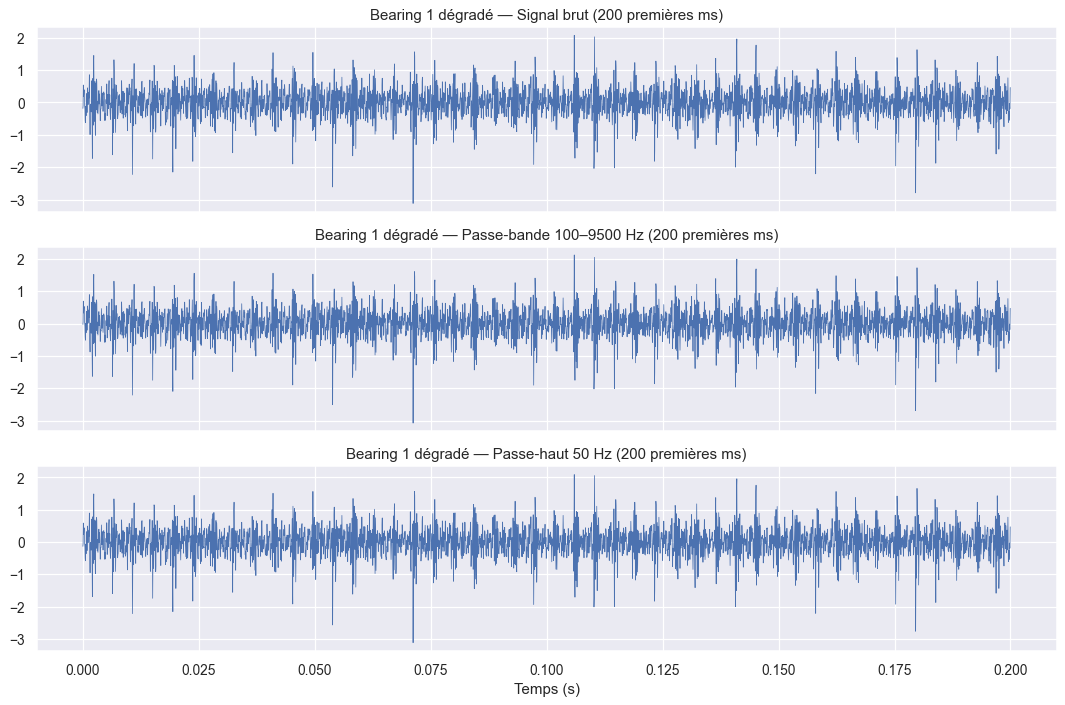

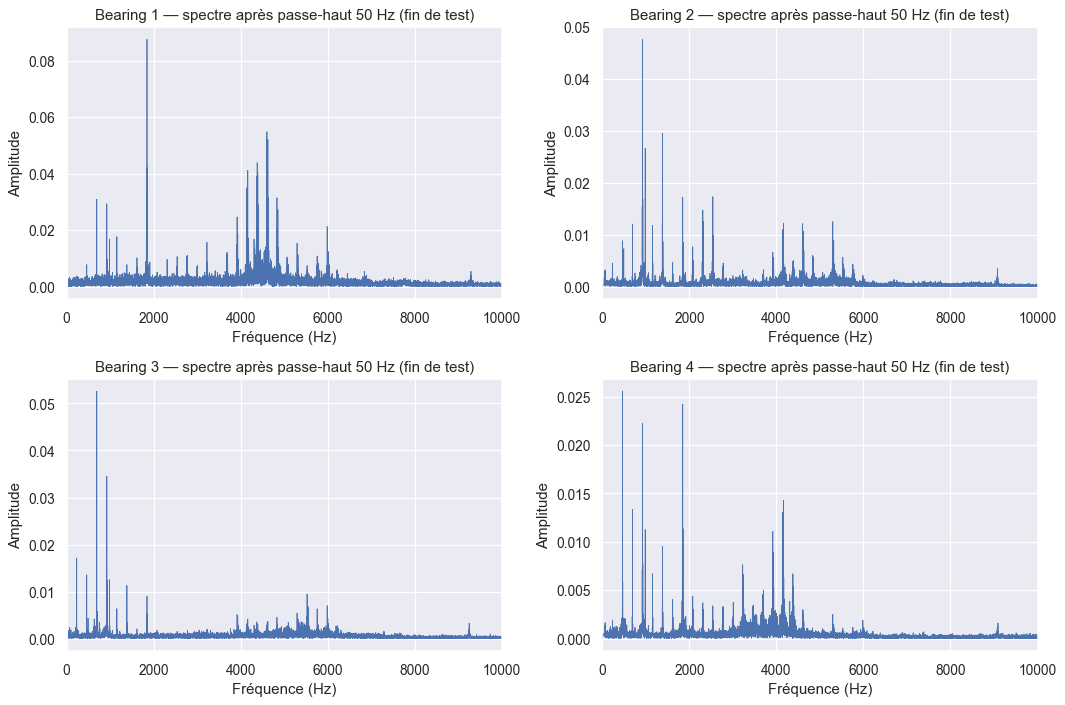

In [13]:
def bandpass_filter(data, lowcut, highcut, fs=FS, order=5):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut / nyq, highcut / nyq], btype='band')
    return filtfilt(b, a, data)

def highpass_filter(data, cutoff, fs=FS, order=5):
    nyq = 0.5 * fs
    b, a = butter(order, cutoff / nyq, btype='high')
    return filtfilt(b, a, data)

x_deg = samples[keys[-1]][:, 0].astype(float)
t = np.arange(len(x_deg)) / FS
x_bp = bandpass_filter(x_deg, 100, 9500)
x_hp = highpass_filter(x_deg, 50)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, s, ti in zip(axes, [x_deg, x_bp, x_hp], ['Signal brut', 'Passe-bande 100–9500 Hz', 'Passe-haut 50 Hz']):
    ax.plot(t[:4000], s[:4000], lw=0.6); ax.set_title(f'Bearing 1 dégradé — {ti} (200 premières ms)')
axes[-1].set_xlabel('Temps (s)'); plt.tight_layout(); plt.show()

# Spectres après passe-haut, 4 roulements, fichier de fin de test
fig, axes = plt.subplots(2, 2, figsize=(12, 8)); axes = axes.flatten()
for i in range(4):
    hp = highpass_filter(samples[keys[-1]][:, i].astype(float), 50)
    f, m = spectrum(hp)
    axes[i].plot(f, m, lw=0.6); axes[i].set_xlim(0, 10000)
    axes[i].set_title(f'Bearing {i+1} — spectre après passe-haut 50 Hz (fin de test)')
    axes[i].set_xlabel('Fréquence (Hz)'); axes[i].set_ylabel('Amplitude')
plt.tight_layout(); plt.show()

### 4.4bis Spectre d'enveloppe et fréquences de défaut

Un défaut localisé produit un **choc à chaque passage d'un élément roulant**. Ces chocs excitent
des résonances haute fréquence ; la **démodulation d'amplitude** (filtre passe-bande 2–8 kHz puis
enveloppe de Hilbert) fait apparaître leur fréquence de répétition, qui dépend de la géométrie du
roulement (Rexnord ZA-2115 : 16 rouleaux, d = 0,331 in, D = 2,815 in, angle de contact 15,17°, 2000 tr/min) :

- **BPFO** (bague extérieure) = n/2 · fr · (1 − d/D·cos α)
- **BPFI** (bague intérieure) = n/2 · fr · (1 + d/D·cos α)
- **BSF** (élément roulant) = D/(2d) · fr · (1 − (d/D·cos α)²)

BPFO = 236.4 Hz | BPFI = 296.9 Hz | BSF = 139.9 Hz | rotation = 33.3 Hz


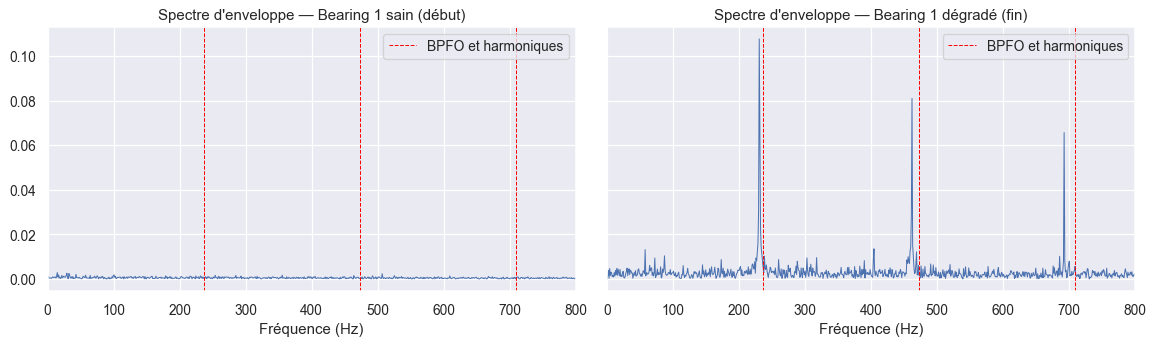

In [14]:
n_r, d, D, alpha, fr = 16, 0.331, 2.815, np.deg2rad(15.17), 2000 / 60
ratio = d / D * np.cos(alpha)
BPFO = n_r / 2 * fr * (1 - ratio)
BPFI = n_r / 2 * fr * (1 + ratio)
BSF = D / (2 * d) * fr * (1 - ratio**2)
print(f"BPFO = {BPFO:.1f} Hz | BPFI = {BPFI:.1f} Hz | BSF = {BSF:.1f} Hz | rotation = {fr:.1f} Hz")

def envelope_spectrum(x, fs=FS):
    xf = bandpass_filter(x - x.mean(), 2000, 8000, fs, order=4)
    env = np.abs(hilbert(xf))
    return spectrum(env, fs)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, k, e in zip(axes, [keys[0], keys[-1]], ['sain (début)', 'dégradé (fin)']):
    f, m = envelope_spectrum(samples[k][:, 0].astype(float))
    ax.plot(f, m, lw=0.8)
    for h in (1, 2, 3):
        ax.axvline(h * BPFO, color='red', ls='--', lw=0.8, label='BPFO et harmoniques' if h == 1 else None)
    ax.set_xlim(0, 800); ax.set_title(f"Spectre d'enveloppe — Bearing 1 {e}")
    ax.set_xlabel('Fréquence (Hz)'); ax.legend()
plt.tight_layout(); plt.show()

**Interprétation** : sur le roulement dégradé, des pics apparaissent près de **BPFO ≈ 236 Hz** et de
ses harmoniques (le léger décalage, ≈ 231 Hz, vient du glissement des rouleaux). Rien de tel sur le
roulement sain : le diagnostic fréquentiel confirme un **défaut de bague extérieure**, cohérent
avec le rapport d'expertise du 2nd test.

### 4.5 Transformée en ondelettes (wavelet) du signal brut

Décomposition **db4 jusqu'au niveau 4** du signal brut (`pywt.wavedec`). À 20 kHz, les bandes
couvertes sont approximativement : cD1 ≈ 5–10 kHz, cD2 ≈ 2,5–5 kHz, cD3 ≈ 1,25–2,5 kHz,
cD4 ≈ 0,6–1,25 kHz, cA4 < 0,6 kHz. Pour chaque niveau : **énergie** et **moyenne** des coefficients.

In [15]:
LEVELS = ['cA4', 'cD4', 'cD3', 'cD2', 'cD1']

def extract_wavelet_features(x, wavelet='db4', level=4):
    coeffs = pywt.wavedec(x - x.mean(), wavelet, level=level)
    return {name: (np.sum(c**2), np.mean(c)) for name, c in zip(LEVELS, coeffs)}

rows = []
for k, e in [(keys[0], 'sain'), (keys[-1], 'dégradé')]:
    for i in range(4):
        for name, (en, mu) in extract_wavelet_features(samples[k][:, i].astype(float)).items():
            rows.append({'État': e, 'Roulement': f'Bearing {i+1}', 'Niveau': name, 'Énergie': en, 'Moyenne': mu})
wav = pd.DataFrame(rows)
wav.pivot_table(index=['Roulement', 'État'], columns='Niveau', values='Énergie')[LEVELS].round(2)

Niveau               cA4     cD4     cD3      cD2      cD1
Roulement État                                            
Bearing 1 dégradé  98.60  248.98  735.15  1892.52  1135.43
          sain     10.04   21.81   16.77    39.52    22.61
Bearing 2 dégradé  32.79  278.86  155.13   170.81   114.72
          sain     17.97   38.13   17.54    45.39    47.40
Bearing 3 dégradé  83.16  219.47   49.91    90.07   117.53
          sain     20.89   18.02   22.36    71.91   107.77
Bearing 4 dégradé  44.38   68.80   65.30   127.98    39.39
          sain     10.97    7.91    6.39    23.28     9.44

### 4.5bis Caractéristiques statistiques par niveau d'ondelette (roulements 1 et 4)

Pour chaque niveau (approximation + détails) on calcule **Énergie**, **Entropie de Shannon**,
**Asymétrie** et **Kurtosis**, sur le signal brut au début et à la fin du test. Le roulement 1
(défaillant) est comparé au roulement 4 (resté sain dans le 2nd test).

Roulement      Moment Niveau  Énergie  Entropie  Asymétrie  Kurtosis
Bearing 1        sain    cA4   10.040     6.856      0.072     0.342
Bearing 1        sain    cD4   21.810     6.958     -0.017    -0.923
Bearing 1        sain    cD3   16.770     7.542      0.055     0.809
Bearing 1        sain    cD2   39.520     8.220     -0.111     1.146
Bearing 1        sain    cD1   22.607     8.908      0.056     0.995
Bearing 1 fin de test    cA4   98.602     6.848      0.033     1.312
Bearing 1 fin de test    cD4  248.981     6.828      0.124     0.314
Bearing 1 fin de test    cD3  735.147     7.607     -0.072    -0.086
Bearing 1 fin de test    cD2 1892.523     8.154     -0.031     2.542
Bearing 1 fin de test    cD1 1135.434     8.843      0.401     3.834
Bearing 4        sain    cA4   10.974     6.865      0.058     0.043
Bearing 4        sain    cD4    7.907     6.890     -0.016    -0.403
Bearing 4        sain    cD3    6.386     7.571      0.026     0.113
Bearing 4        sain    cD2   23.

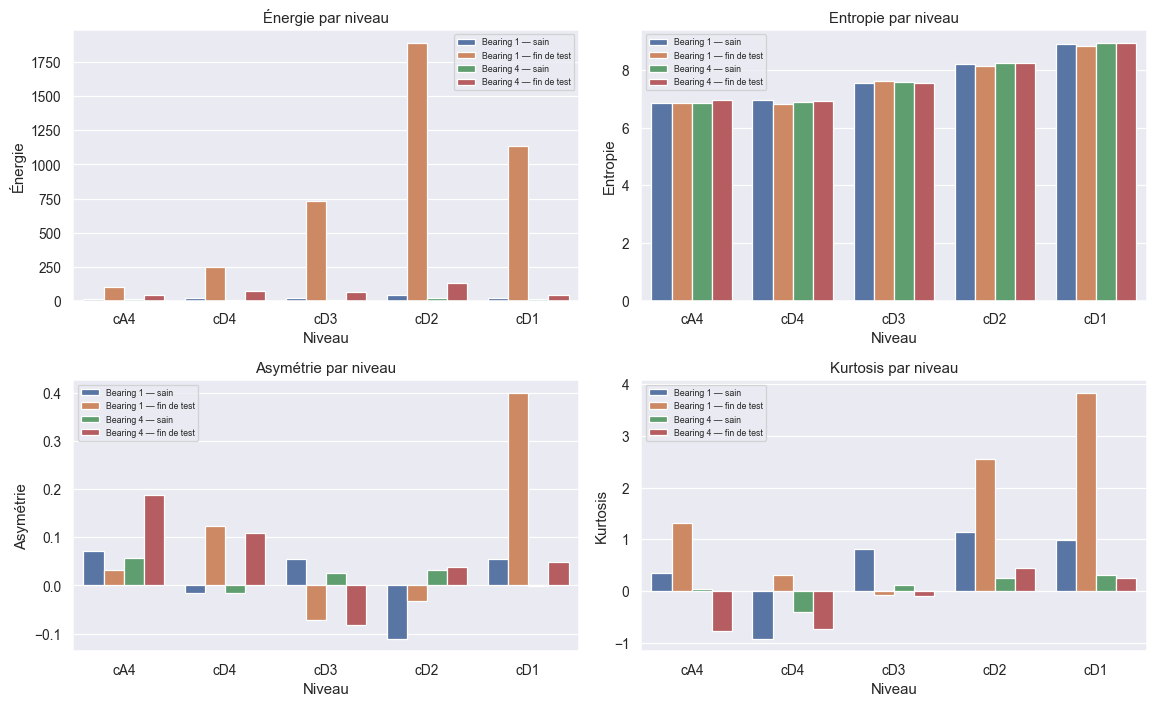

In [16]:
def shannon_entropy(x):
    p = np.abs(x) / (np.sum(np.abs(x)) + 1e-12)
    return float(-np.sum(p * np.log(p + 1e-12)))

stats = []
for b in (1, 4):
    for k, e in [(keys[0], 'sain'), (keys[-1], 'fin de test')]:
        x = samples[k][:, b - 1].astype(float)
        for name, c in zip(LEVELS, pywt.wavedec(x - x.mean(), 'db4', level=4)):
            stats.append({'Roulement': f'Bearing {b}', 'Moment': e, 'Niveau': name,
                          'Énergie': np.sum(c**2), 'Entropie': shannon_entropy(c),
                          'Asymétrie': skew(c), 'Kurtosis': kurtosis(c)})
stats_w = pd.DataFrame(stats)
print(stats_w.round(3).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(13, 8)); axes = axes.flatten()
for ax, col in zip(axes, ['Énergie', 'Entropie', 'Asymétrie', 'Kurtosis']):
    sns.barplot(data=stats_w, x='Niveau', y=col, hue=stats_w['Roulement'] + ' — ' + stats_w['Moment'], ax=ax)
    ax.set_title(f'{col} par niveau'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Interprétation** : en fin de test, l'énergie du **Bearing 1** est multipliée par **45 à 50** dans les
niveaux de détail cD1–cD3 (1,25–10 kHz) et son kurtosis en cD1 passe de 1,0 à 3,8 : signature de chocs
répétés. Le **Bearing 4**, resté sain, voit aussi son énergie augmenter (toute la machine vibre plus
en fin d'essai), mais seulement d'un facteur 4 à 10, sans hausse du kurtosis.

## 5. Data Labelling (étiquetage Healthy / Faulty)

Pour chaque acquisition et chaque roulement, on utilise 4 attributs du signal brut :
**RMS, Énergie, Entropie spectrale, Kurtosis** (calculés par `extract_features.py`).
Seuils par **IQR × 1,5** : un échantillon est *faulty (1)* s'il sort de l'intervalle
[Q1 − 1,5·IQR ; Q3 + 1,5·IQR] sur au moins un attribut, sinon *healthy (0)*.

In [17]:
feature_names = FEATS  # ['RMS', 'Energy', 'Entropy', 'Kurtosis']
features = {f'Bearing_{i}': feat2[feat2.Bearing == i].set_index('File')[feature_names] for i in range(1, 5)}
files = features['Bearing_1'].index

labels = pd.DataFrame(index=files)
for b, fb in features.items():
    faulty = np.zeros(len(fb), dtype=bool)
    for feat in feature_names:
        q1, q3 = fb[feat].quantile(0.25), fb[feat].quantile(0.75)
        iqr_ = q3 - q1
        faulty |= ((fb[feat] < q1 - 1.5 * iqr_) | (fb[feat] > q3 + 1.5 * iqr_)).to_numpy()
    labels[b] = faulty.astype(int)

pd.DataFrame({'Healthy': (labels == 0).sum(), 'Faulty': (labels == 1).sum()})

,Healthy,Faulty
Bearing_1,776,208
Bearing_2,854,130
Bearing_3,848,136
Bearing_4,835,149


> **Limite à expliquer au jury** : les labels sont définis par des seuils sur RMS/Énergie/Entropie/Kurtosis,
> et les classifieurs reçoivent **ces mêmes attributs** en entrée. Ils réapprennent donc la règle de seuil :
> une accuracy proche de 100 % est attendue et mesure surtout la capacité à reproduire cette règle,
> pas à détecter un défaut « réel ». C'est pourquoi la section 6.3 ajoute un test plus exigeant.

## 6. Modèles d'apprentissage machine classiques

Objectif : classer chaque échantillon **healthy (0) / faulty (1)** pour chacun des 4 roulements.
Évaluation par **cross-validation 5-fold stratifiée**, matrices de confusion.
Modèles : **Logistic Regression, Random Forest, Decision Tree, SVM, KNN, XGBoost**.

In [18]:
X_frames = []
for i in range(1, 5):
    fb = features[f'Bearing_{i}'].reset_index(drop=True)
    fb.columns = [f'Bearing_{i}_{c}' for c in fb.columns]
    X_frames.append(fb)
X = pd.concat(X_frames, axis=1)
Y = labels.reset_index(drop=True)
print("X shape :", X.shape, "| Y shape :", Y.shape)

X shape : (984, 16) | Y shape : (984, 4)


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GroupKFold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=42)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                             eval_metric='logloss', random_state=42, verbosity=0),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def scores(y, yp):
    cm = confusion_matrix(y, yp, labels=[0, 1])
    return {'Accuracy': accuracy_score(y, yp), 'Precision': precision_score(y, yp, zero_division=0),
            'Recall': recall_score(y, yp, zero_division=0), 'F1': f1_score(y, yp, zero_division=0),
            'FP': int(cm[0, 1]), 'FN': int(cm[1, 0])}

summary, cv_preds = [], {}
for name, model in models.items():
    for b in Y.columns:
        yp = cross_val_predict(model, X, Y[b], cv=cv)
        cv_preds[(name, b)] = yp
        summary.append({'Model': name, 'Bearing': b, **scores(Y[b], yp)})
res = pd.DataFrame(summary)
res.round(4).to_csv('resultats_ml_per_bearing.csv', index=False)
print(res.round(4).to_string(index=False))

              Model   Bearing  Accuracy  Precision  Recall     F1  FP  FN
Logistic Regression Bearing_1    0.9909     0.9807  0.9760 0.9783   4   5
Logistic Regression Bearing_2    0.9715     0.9811  0.8000 0.8814   2  26
Logistic Regression Bearing_3    0.9665     0.9640  0.7868 0.8664   4  29
Logistic Regression Bearing_4    0.9726     0.9420  0.8725 0.9059   8  19
      Random Forest Bearing_1    0.9939     0.9903  0.9808 0.9855   2   4
      Random Forest Bearing_2    0.9929     0.9843  0.9615 0.9728   2   5
      Random Forest Bearing_3    0.9970     1.0000  0.9779 0.9888   0   3
      Random Forest Bearing_4    0.9980     1.0000  0.9866 0.9932   0   2
      Decision Tree Bearing_1    0.9909     0.9761  0.9808 0.9784   5   4
      Decision Tree Bearing_2    0.9949     0.9921  0.9692 0.9805   1   4
      Decision Tree Bearing_3    0.9980     1.0000  0.9853 0.9926   0   2
      Decision Tree Bearing_4    1.0000     1.0000  1.0000 1.0000   0   0
                SVM Bearing_1    0.991

### 6.1 Matrices de confusion (Random Forest, 4 roulements)

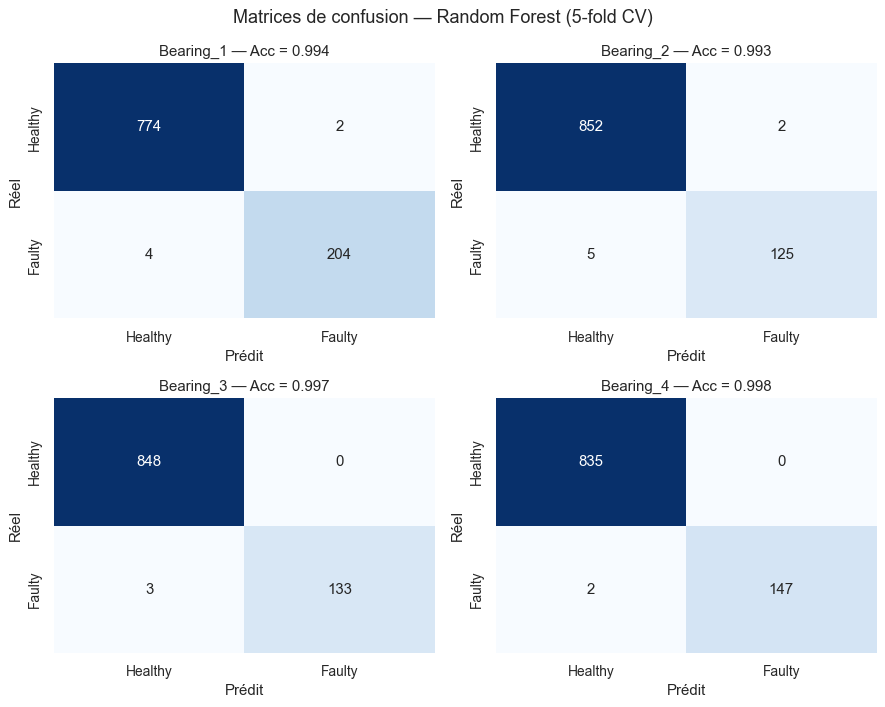

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8)); axes = axes.flatten()
for ax, b in zip(axes, Y.columns):
    yp = cv_preds[('Random Forest', b)]
    sns.heatmap(confusion_matrix(Y[b], yp), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Healthy', 'Faulty'], yticklabels=['Healthy', 'Faulty'])
    ax.set_title(f'{b} — Acc = {accuracy_score(Y[b], yp):.3f}'); ax.set_xlabel('Prédit'); ax.set_ylabel('Réel')
fig.suptitle('Matrices de confusion — Random Forest (5-fold CV)'); plt.tight_layout(); plt.show()

### 6.2 Résultats chiffrés (moyenne sur les 4 roulements)

In [21]:
res.groupby('Model')[['Accuracy', 'Precision', 'Recall', 'F1']].mean().sort_values('F1', ascending=False).round(3)

,Accuracy,Precision,Recall,F1
Model,,,,
Decision Tree,0.996,0.992,0.984,0.988
Random Forest,0.995,0.994,0.977,0.985
XGBoost,0.996,0.996,0.974,0.985
KNN,0.978,0.954,0.897,0.923
SVM,0.979,0.982,0.870,0.921
Logistic Regression,0.975,0.967,0.859,0.908


Les modèles à base d'arbres (**Decision Tree, Random Forest, XGBoost**) atteignent F1 ≈ 0,985 :
c'est attendu, car une règle de seuil IQR est exactement ce qu'un arbre de décision sait représenter.
Les modèles linéaires ou à distance (LR, SVM, KNN) ratent davantage de *faulty* (recall 0,86–0,90).

### 6.3 Test plus exigeant : généralisation à un roulement jamais vu

En 6.0–6.2, chaque roulement a son propre modèle et les acquisitions d'entraînement et de test sont
voisines dans le temps. Ici on empile les 4 roulements (1 ligne = 1 acquisition d'un roulement,
4 attributs) et on évalue en **leave-one-bearing-out** : on entraîne sur 3 roulements et on teste sur le 4e.
Les attributs sont exprimés **par rapport au roulement neuf** (ratio à la médiane des 200 premières
acquisitions), sinon les écarts de niveau entre roulements dominent.

In [22]:
stack = []
for i in range(1, 5):
    fb = features[f'Bearing_{i}']
    Xr = np.log(relative_features(fb.to_numpy(), fb.iloc[:N_BASE].median().to_numpy()))
    stack.append(pd.DataFrame(Xr, columns=FEATS).assign(y=labels[f'Bearing_{i}'].to_numpy(), group=i))
stack = pd.concat(stack, ignore_index=True)

rows = []
for name, model in models.items():
    yp = cross_val_predict(model, stack[FEATS], stack['y'], groups=stack['group'], cv=GroupKFold(4))
    rows.append({'Model': name, **scores(stack['y'], yp)})
pd.DataFrame(rows).set_index('Model').round(3).sort_values('F1', ascending=False)

,Accuracy,Precision,Recall,F1,FP,FN
Model,,,,,,
SVM,0.883,0.604,0.762,0.674,312,148
Random Forest,0.858,0.536,0.754,0.627,407,153
XGBoost,0.853,0.524,0.766,0.622,433,146
KNN,0.845,0.507,0.762,0.609,462,148
Decision Tree,0.841,0.498,0.769,0.605,482,144
Logistic Regression,0.876,0.614,0.573,0.593,224,266


**Interprétation** : sur un roulement jamais vu, le F1 tombe à **0,59–0,67** (contre ≈ 0,99 en 5-fold).
Les seuils IQR étant calculés roulement par roulement, la frontière healthy/faulty d'un roulement ne se
transpose qu'en partie aux autres. C'est ce chiffre qu'il faut retenir pour un déploiement sur une
nouvelle machine ; le score en 5-fold mesure la cohérence avec la règle d'étiquetage.

## 7. Prédiction de la Durée de Vie Résiduelle (RUL)

**Réponse à la question « faut-il travailler sur la data qui a la panne ? » : oui.**
La RUL se définit par rapport à l'instant de panne : RUL = (T_panne − T_actuelle) en jours.
Seuls les roulements qui **vont jusqu'à la casse** (*run-to-failure*) ont une RUL connue.
Les roulements 2, 3, 4 du 2nd test ne cassent pas : leur RUL est inconnue, ils ne peuvent pas servir de cible.

Le 2nd test ne fournit qu'**une seule** trajectoire de panne (Bearing 1). Pour entraîner **et** évaluer
honnêtement un modèle, on utilise les **4 pannes des 3 tests IMS**.

### 7.1 Les 4 trajectoires de panne

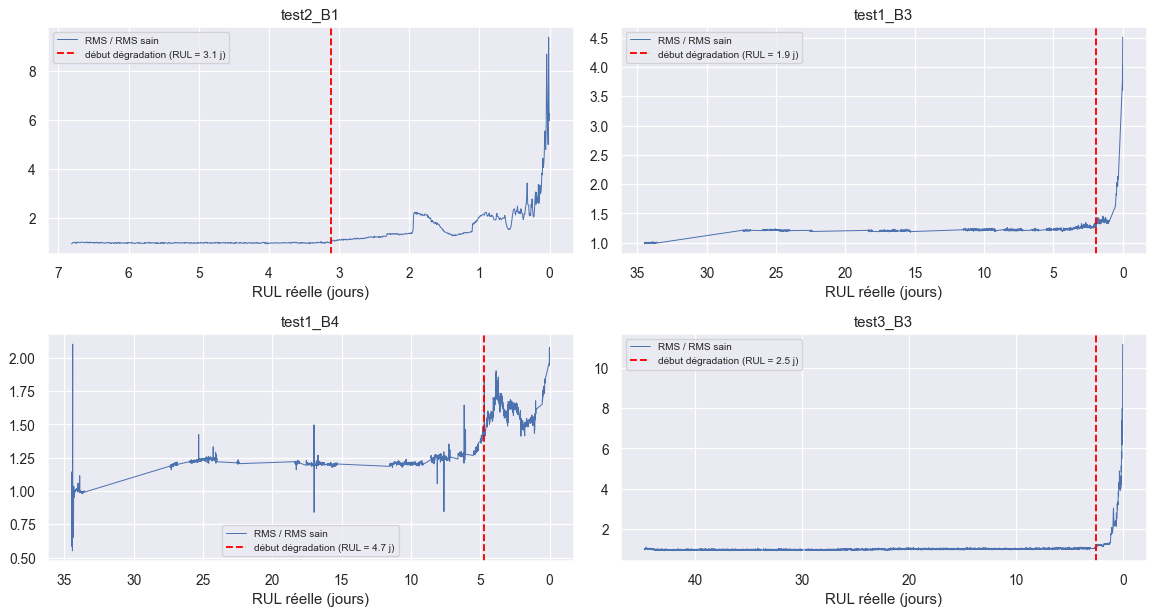

,Acquisitions,Durée (j),RMS sain (g),RUL au début de la dégradation (j)
test2_B1,982.0,6.812,0.077,3.118
test1_B3,2156.0,34.482,0.132,1.895
test1_B4,2156.0,34.482,0.113,4.712
test3_B3,6323.0,44.712,0.068,2.465


In [23]:
traj = {k: failure_trajectory(*v) for k, v in FAILURES.items()}
onsets = {k: degradation_onset(b) for k, b in traj.items()}

fig, axes = plt.subplots(2, 2, figsize=(13, 7)); axes = axes.flatten()
for ax, (k, b) in zip(axes, traj.items()):
    rel = relative_features(b[FEATS].to_numpy(), healthy_reference(b))
    ax.plot(b['RUL'], rel[:, 0], lw=0.8, label='RMS / RMS sain')
    ax.axvline(b['RUL'][onsets[k]], color='red', ls='--', label=f"début dégradation (RUL = {b['RUL'][onsets[k]]:.1f} j)")
    ax.invert_xaxis(); ax.set_xlabel('RUL réelle (jours)'); ax.set_title(k); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

pd.DataFrame({k: {'Acquisitions': len(b), 'Durée (j)': b['RUL'].max(),
                  'RMS sain (g)': healthy_reference(b)[0],
                  'RUL au début de la dégradation (j)': b['RUL'][onsets[k]]}
              for k, b in traj.items()}).T.round(3)

**Observations** :
- les niveaux de vibration « sains » diffèrent d'un test à l'autre (capteurs, montage) → on exprime
  chaque attribut **par rapport au roulement neuf** (ratio à la médiane des 200 premières acquisitions,
  puis logarithme : 0 = état sain) ;
- la durée totale varie de 7 à 45 jours, mais la dégradation commence toujours **2 à 5 jours avant la panne**.
  Pendant la phase saine, le signal est plat : **aucun modèle ne peut deviner** s'il reste 10 ou 40 jours.
- dans le **1st test**, l'enregistrement est interrompu **6,2 jours** après 0,9 jour d'essai (acquisition n° 156,
  segment rectiligne sur les courbes) ; à la reprise, le niveau de vibration a augmenté de ~20 %.
  La référence « roulement neuf » (200 premières acquisitions) est à cheval sur cette interruption,
  donc moins représentative pour ces deux roulements.

### 7.2 Cible RUL linéaire par morceaux

La pratique standard en pronostic (ex. benchmark NASA C-MAPSS) est une RUL **plafonnée** :
tant que le roulement est sain, la cible vaut une constante `CAP` ; ensuite elle décroît linéairement.
On prend **CAP = 3 jours**, ordre de grandeur de la phase de dégradation observée.
Le modèle répond donc « au moins 3 jours » quand tout va bien, puis donne un compte à rebours.

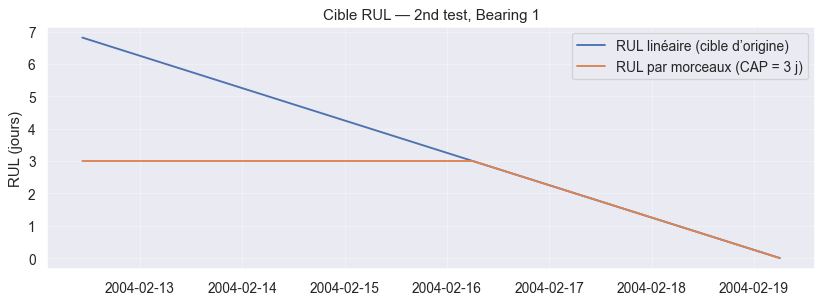

In [24]:
CAP = 3.0
b = traj['test2_B1']
plt.figure(figsize=(11, 3.5))
plt.plot(b['Date'], b['RUL'], label='RUL linéaire (cible d’origine)')
plt.plot(b['Date'], piecewise_rul(b['RUL'], CAP), label=f'RUL par morceaux (CAP = {CAP:.0f} j)')
plt.ylabel('RUL (jours)'); plt.title('Cible RUL — 2nd test, Bearing 1'); plt.legend(); plt.grid(alpha=.3); plt.show()

### 7.3 Pourquoi le split aléatoire des fenêtres est trompeur

Le protocole d'origine découpait **une seule** trajectoire en fenêtres glissantes, puis les mélangeait
(`train_test_split(shuffle=True)`). Deux fenêtres voisines partagent 29 points sur 30 : le jeu de test
contient donc des quasi-copies du jeu d'entraînement. De plus, l'early stopping utilisait le jeu de test.

Démonstration : on compare le CNN-LSTM à un Random Forest qui ne reçoit **que le numéro de l'acquisition**
(aucune information de vibration).

In [25]:
from sklearn.model_selection import train_test_split

X_raw = b[FEATS].to_numpy(); rul_lin = b['RUL'].to_numpy()
Xw, yw = sliding_windows(MinMaxScaler().fit_transform(X_raw), rul_lin)
Xtr, Xte, ytr, yte = train_test_split(Xw, yw, test_size=0.2, random_state=42, shuffle=True)
m = build_cnn_lstm(); fit_keras(m, Xtr, ytr, Xte, yte, epochs=80, patience=10)
r_cnn = metrics(yte, m.predict(Xte, verbose=0).ravel())

idx_w = np.arange(len(b))[WINDOW - 1:].reshape(-1, 1).astype(float)
Itr, Ite, _, _ = train_test_split(idx_w, yw, test_size=0.2, random_state=42, shuffle=True)
r_idx = metrics(yte, RandomForestRegressor(200, random_state=0).fit(Itr, ytr).predict(Ite))

pd.DataFrame({'CNN-LSTM (4 features)': r_cnn, "RF sur le n° d'acquisition seul": r_idx}).T.round(3)

,R2,MAE,RMSE
CNN-LSTM (4 features),0.923,0.385,0.528
RF sur le n° d'acquisition seul,1.000,0.004,0.005


Un modèle qui **ne voit aucune vibration** obtient R² ≈ 1 : avec ce protocole, le score mesure la
capacité à interpoler dans le temps, pas à pronostiquer. Les R² de 0,85 à 0,92 annoncés précédemment
ne sont donc **pas** des performances de prédiction.

### 7.4 Évaluation honnête : validation croisée par panne (leave-one-failure-out)

On entraîne sur 3 pannes et on prédit la 4e (roulement **et** test jamais vus), en tournant.
- Entrée : fenêtre de **30 acquisitions** (5 h) × 4 attributs relatifs au roulement neuf (log-ratio).
- Cible : RUL par morceaux (CAP = 3 j).
- La longue phase saine est sous-échantillonnée (1 fenêtre sur 5) pour équilibrer l'apprentissage.
- 15 % des fenêtres d'entraînement servent à l'early stopping ; la panne testée n'est jamais utilisée.
- Modèles : **référence constante** (toujours CAP), **Random Forest** (résumé de la fenêtre),
  **LSTM**, **hybridation CNN-LSTM**.
- Métrique principale : MAE et RMSE **pendant la phase de dégradation** (RUL < CAP), là où l'opérateur en a besoin.

In [26]:
def prepare(b):
    Xr = np.log(relative_features(b[FEATS].to_numpy(), healthy_reference(b)))
    Xw, yw = sliding_windows(Xr, piecewise_rul(b['RUL'].to_numpy(), CAP))
    return Xw, yw, b['RUL'].to_numpy()[WINDOW - 1:]

def summarize(Xw):  # résumé de fenêtre pour le Random Forest
    return np.concatenate([Xw[:, -1], Xw.mean(1), Xw.max(1)], axis=1)

def train_set(keys_, seed=0):
    Xs, ys = [], []
    for k in keys_:
        Xw, yw, _ = data[k]
        keep = (yw < CAP) | (np.arange(len(yw)) % 5 == 0)
        Xs.append(Xw[keep]); ys.append(yw[keep])
    X_, y_ = np.concatenate(Xs), np.concatenate(ys)
    perm = np.random.default_rng(seed).permutation(len(X_)); nv = int(0.15 * len(X_))
    return X_[perm[nv:]], y_[perm[nv:]], X_[perm[:nv]], y_[perm[:nv]]

data = {k: prepare(b) for k, b in traj.items()}
preds, rows = {}, []
for test in data:
    Xtr, ytr, Xva, yva = train_set([k for k in data if k != test])
    Xte, yte, _ = data[test]
    p = {'Constante (CAP)': np.full(len(yte), CAP),
         'Random Forest': RandomForestRegressor(300, min_samples_leaf=5, random_state=0, n_jobs=-1)
                          .fit(summarize(np.concatenate([Xtr, Xva])), np.concatenate([ytr, yva]))
                          .predict(summarize(Xte))}
    for name, build in [('LSTM', build_lstm), ('CNN-LSTM', build_cnn_lstm)]:
        mdl = build(); fit_keras(mdl, Xtr, ytr, Xva, yva, epochs=80, patience=10)
        p[name] = mdl.predict(Xte, verbose=0).ravel()
    deg = yte < CAP
    for name, yp in p.items():
        yp = np.clip(yp, 0, None); p[name] = yp
        rows.append({'Panne testée': test, 'Modèle': name,
                     'MAE dégradation (j)': np.abs(yp - yte)[deg].mean(),
                     'RMSE dégradation (j)': np.sqrt(np.mean((yp - yte)[deg] ** 2)),
                     'MAE globale (j)': np.abs(yp - yte).mean()})
    preds[test] = p
    print(f'{test} terminé')

lofo = pd.DataFrame(rows)
lofo.pivot(index='Modèle', columns='Panne testée', values='MAE dégradation (j)').round(2)

test2_B1 terminé


test1_B3 terminé


test1_B4 terminé


test3_B3 terminé


Panne testée,test1_B3,test1_B4,test2_B1,test3_B3
Modèle,,,,
CNN-LSTM,1.11,1.00,0.95,0.61
Constante (CAP),1.19,1.19,1.50,1.65
LSTM,1.12,0.83,0.68,0.57
Random Forest,0.79,0.89,0.55,0.70


In [27]:
recap = lofo.groupby('Modèle')[['MAE dégradation (j)', 'RMSE dégradation (j)', 'MAE globale (j)']].mean()
recap.sort_values('MAE dégradation (j)').round(3)

,MAE dégradation (j),RMSE dégradation (j),MAE globale (j)
Modèle,,,
Random Forest,0.732,0.906,0.401
LSTM,0.799,0.976,0.314
CNN-LSTM,0.919,1.112,0.499
Constante (CAP),1.383,1.602,0.279


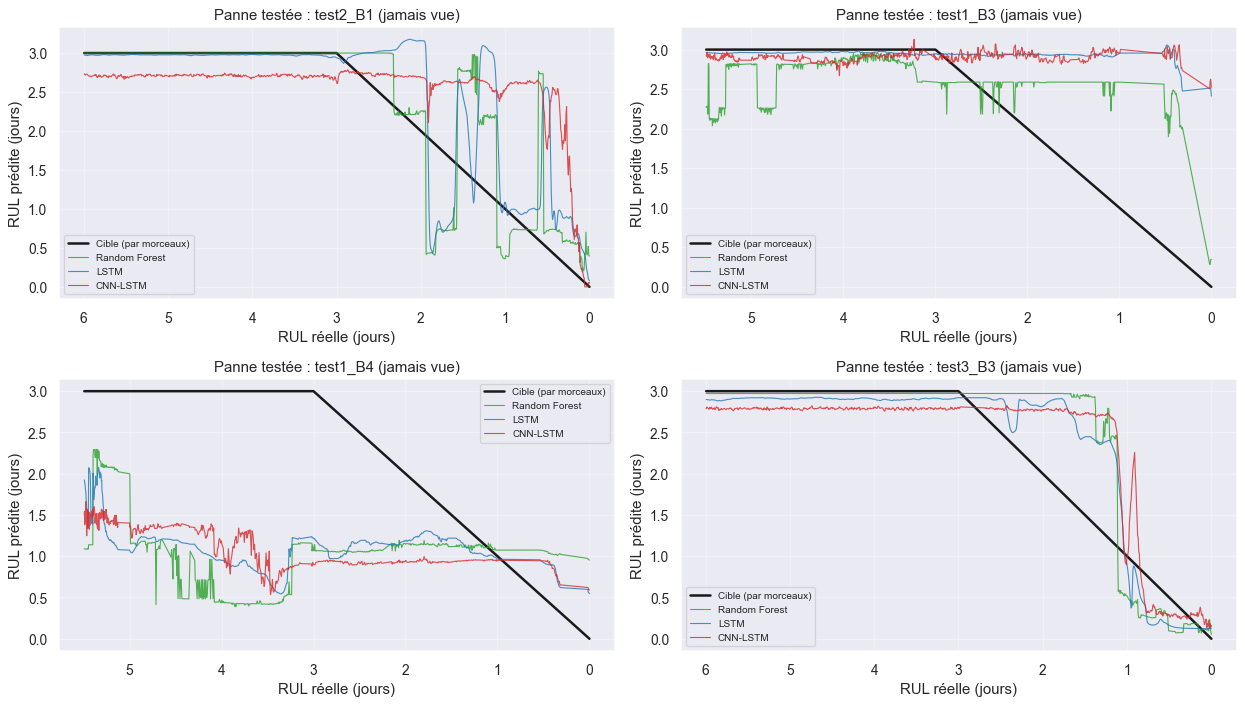

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8)); axes = axes.flatten()
for ax, (k, p) in zip(axes, preds.items()):
    _, yte, rul_true = data[k]
    deg = rul_true < 2 * CAP  # zoom sur les derniers jours
    ax.plot(rul_true[deg], yte[deg], 'k', lw=2, label='Cible (par morceaux)')
    for name, c in [('Random Forest', 'tab:green'), ('LSTM', 'tab:blue'), ('CNN-LSTM', 'tab:red')]:
        ax.plot(rul_true[deg], p[name][deg], c=c, lw=0.9, alpha=0.8, label=name)
    ax.invert_xaxis(); ax.set_xlabel('RUL réelle (jours)'); ax.set_ylabel('RUL prédite (jours)')
    ax.set_title(f'Panne testée : {k} (jamais vue)'); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.5 Lecture des résultats

Erreur moyenne pendant la phase de dégradation (moyenne sur les 4 pannes jamais vues) :
**Random Forest 0,73 j**, **LSTM 0,80 j**, **CNN-LSTM 0,92 j**, contre **1,38 j** pour la référence constante.

- **Tous les modèles apprennent quelque chose** (erreur réduite de 33 à 47 % par rapport à la référence),
  mais avec seulement **4 pannes**, la RUL n'est que **partiellement prévisible** : l'erreur reste de l'ordre du jour.
- **Le modèle le plus simple fait au moins aussi bien** : le Random Forest sur un résumé de la fenêtre
  (dernière valeur, moyenne, maximum) devance le LSTM et le CNN-LSTM. Avec si peu de trajectoires,
  les réseaux profonds n'ont pas assez d'exemples pour exploiter leur capacité supplémentaire.
  Les écarts entre modèles restent du même ordre que la variabilité d'une panne à l'autre.
- **Comportement par panne** :
  - *test3_B3* et *test2_B1* : la RUL prédite chute à l'approche de la panne (bon suivi, avec des oscillations pour test2_B1) ;
  - *test1_B3* : dégradation tardive et brutale, mal anticipée (seul le Random Forest réagit dans les dernières heures) ;
  - *test1_B4* : RUL prédite ≈ 1 j dès le début → **fausse alarme précoce**, liée au saut de niveau
    après l'interruption de l'enregistrement du 1st test (référence peu représentative, voir 7.1).
- Dans **3 cas sur 4**, la RUL prédite passe sous 1 jour avant la casse : pour l'opérateur, l'information
  fiable est le **passage sain → dégradé → critique**, plus que la valeur exacte de la RUL.

Ces chiffres sont plus modestes que les R² d'origine, mais ils sont **défendables** devant un jury :
ils mesurent la prédiction sur un roulement réellement inconnu.

### 7.6 Modèle final pour le jumeau numérique

L'hybridation **CNN-LSTM** est réentraînée sur les **4 pannes** et ses poids sont exportés au format
lu par l'interface `rul_4feat.html` (inférence 100 % JavaScript, même architecture).

> Choix assumé : le CNN-LSTM n'est pas le meilleur modèle en 7.4 (le Random Forest fait un peu mieux),
> mais les écarts restent dans la variabilité entre pannes et l'architecture CNN-LSTM est celle déjà
> intégrée à l'interface. Remplacer le modèle de l'interface par le Random Forest est une piste d'amélioration.

In [29]:
import json
Xtr, ytr, Xva, yva = train_set(list(data))
final = build_cnn_lstm(); fit_keras(final, Xtr, ytr, Xva, yva, epochs=80, patience=10)
final.save('cnn_lstm_rul.keras')

L = {l.name: l for l in final.layers}
conv = [l for l in final.layers if l.__class__.__name__ == 'Conv1D']
bn = [l for l in final.layers if l.__class__.__name__ == 'BatchNormalization']
lstm = [l for l in final.layers if l.__class__.__name__ == 'LSTM'][0]
dense = [l for l in final.layers if l.__class__.__name__ == 'Dense']
flat = lambda a: np.asarray(a, dtype=np.float32).ravel().round(6).tolist()
W = {}
for i, (c, n) in enumerate(zip(conv, bn), start=1):
    k, bias = c.get_weights(); g, beta, mm, mv = n.get_weights()
    W.update({f'conv{i}_k': flat(k), f'conv{i}_b': flat(bias),
              f'bn{i}_g': flat(g), f'bn{i}_b': flat(beta), f'bn{i}_m': flat(mm), f'bn{i}_v': flat(mv)})
lk, lu, lb = lstm.get_weights()
W.update({'lstm_k': flat(lk), 'lstm_u': flat(lu), 'lstm_b': flat(lb),
          'dense1_w': flat(dense[0].get_weights()[0]), 'dense1_b': flat(dense[0].get_weights()[1]),
          'dense2_w': flat(dense[1].get_weights()[0]), 'dense2_b': flat(dense[1].get_weights()[1])})

# Démos de l'interface : 2nd test Bearing 1 (référence = 200 premières acquisitions)
b = traj['test2_B1']
demo = {'ref': b[FEATS].iloc[:N_BASE].to_numpy().tolist(),
        'healthy': b[FEATS].iloc[300:330].to_numpy().tolist(),
        'degraded': b[FEATS].iloc[-WINDOW:].to_numpy().tolist()}
with open('twin_weights.json', 'w') as f:
    json.dump({'weights': W, 'cap': CAP, 'window': WINDOW, 'n_base': N_BASE, 'demo': demo,
               'lofo': recap.round(3).reset_index().to_dict('records')}, f)

# Vérification : RUL prédite sur les deux démos
for name in ('healthy', 'degraded'):
    Xd = np.log(relative_features(np.array(demo[name]), np.median(demo['ref'], axis=0)))
    print(name, '-> RUL prédite =', round(float(final.predict(Xd[None], verbose=0)[0, 0]), 3), 'j')
print('Poids exportés dans twin_weights.json')

healthy -> RUL prédite = 2.853 j
degraded -> RUL prédite = -0.095 j
Poids exportés dans twin_weights.json


## 8. Jumeau numérique (interface opérateur)

L'interface `rul_4feat.html` s'ouvre dans un navigateur, sans installation. Pour un opérateur qui ne
connaît pas le machine learning :
1. il charge le **dossier d'acquisitions** du roulement (fichiers bruts, 1 fichier toutes les 10 min) ;
2. la page calcule elle-même RMS, Énergie, Entropie et Kurtosis pour chaque fichier ;
3. les **200 premières acquisitions** servent de référence « roulement neuf », les **30 plus récentes**
   forment la fenêtre analysée par le CNN-LSTM ;
4. la page affiche un état simple : **NORMAL** (RUL ≥ 2,5 j), **SURVEILLANCE** (1–2,5 j),
   **ARRÊT RECOMMANDÉ** (< 1 j), avec la RUL estimée et l'évolution des indicateurs.

S'il manque des acquisitions (moins de 230 fichiers), la page **refuse l'analyse** au lieu de compléter
avec des données fictives : un résultat rassurant mais faux serait dangereux pour l'opérateur.

## Conclusion

- **EDA et analyse fréquentielle** : le Bearing 1 du 2nd test montre une dégradation nette sur les
  3 derniers jours ; le spectre d'enveloppe du signal brut fait apparaître la fréquence de défaut de bague
  extérieure (BPFO ≈ 236 Hz), ce qui confirme le diagnostic.
- **Classification healthy/faulty** : les scores sont très élevés, mais les labels étant construits à partir
  des mêmes attributs, ils mesurent surtout la reproduction de la règle IQR. Le test sur un roulement
  jamais vu (6.3) donne une estimation plus réaliste.
- **RUL** : la prédiction nécessite des données qui vont **jusqu'à la panne**. Le protocole d'origine
  (fenêtres mélangées, R² ≈ 0,92) surestimait fortement les performances : un modèle sans aucune information
  de vibration y obtient R² = 1. Évalués sur une panne jamais vue (4 pannes, 3 tests IMS), les modèles
  réduisent l'erreur de 33 à 47 % par rapport à une prédiction constante (MAE ≈ 0,7–0,9 j pendant la
  dégradation) ; le Random Forest, plus simple, fait au moins aussi bien que les réseaux profonds.
- **Jumeau numérique** : l'interface embarque le CNN-LSTM entraîné sur les 4 pannes, calcule les
  attributs à partir de la vibration brute et traduit la RUL en consigne simple pour l'opérateur.

**Perspectives** : davantage de trajectoires de panne (dataset PRONOSTIA / FEMTO, XJTU-SY), un indicateur
de santé monotone, et une estimation d'incertitude (intervalle de RUL) plutôt qu'une valeur unique.